In [30]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np
from sklearn.model_selection import train_test_split

### Setting Base Theme and Color Palettes For Target

In [31]:
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.7)
PALETTE = {"Non-Fatal": "#4C72B0", "Fatal": "#DD8452"}

### Reading in Cleaned Data and Train Test Split

In [32]:
df = pd.read_excel("data/raw/Aggregated_Flood_Data.xlsx", sheet_name="Aggregated")

start = pd.to_datetime(df["Start Date"], errors="coerce")
end = pd.to_datetime(df["End Date"], errors="coerce")
df["Duration"] = (end - start).dt.days.clip(lower=0)

df = df[df["Year"].between(1900, 2026)].dropna(subset=["Fatalities"])

numeric_features = ["Year", "Lat", "Lon", "Duration", "Affected", "Injured"]
categorical_features = ["Country"]

X = df[numeric_features + categorical_features]
y = (df["Fatalities"] >= 1).astype(int)

X.shape, y.value_counts(normalize=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=522
)

train_df = X_train.assign(Fatal=y_train)
train_df["Outcome"] = train_df["Fatal"].map({0: "Non-Fatal", 1: "Fatal"})


### Fig 1 - Reported Flood Impact by Fatality Status

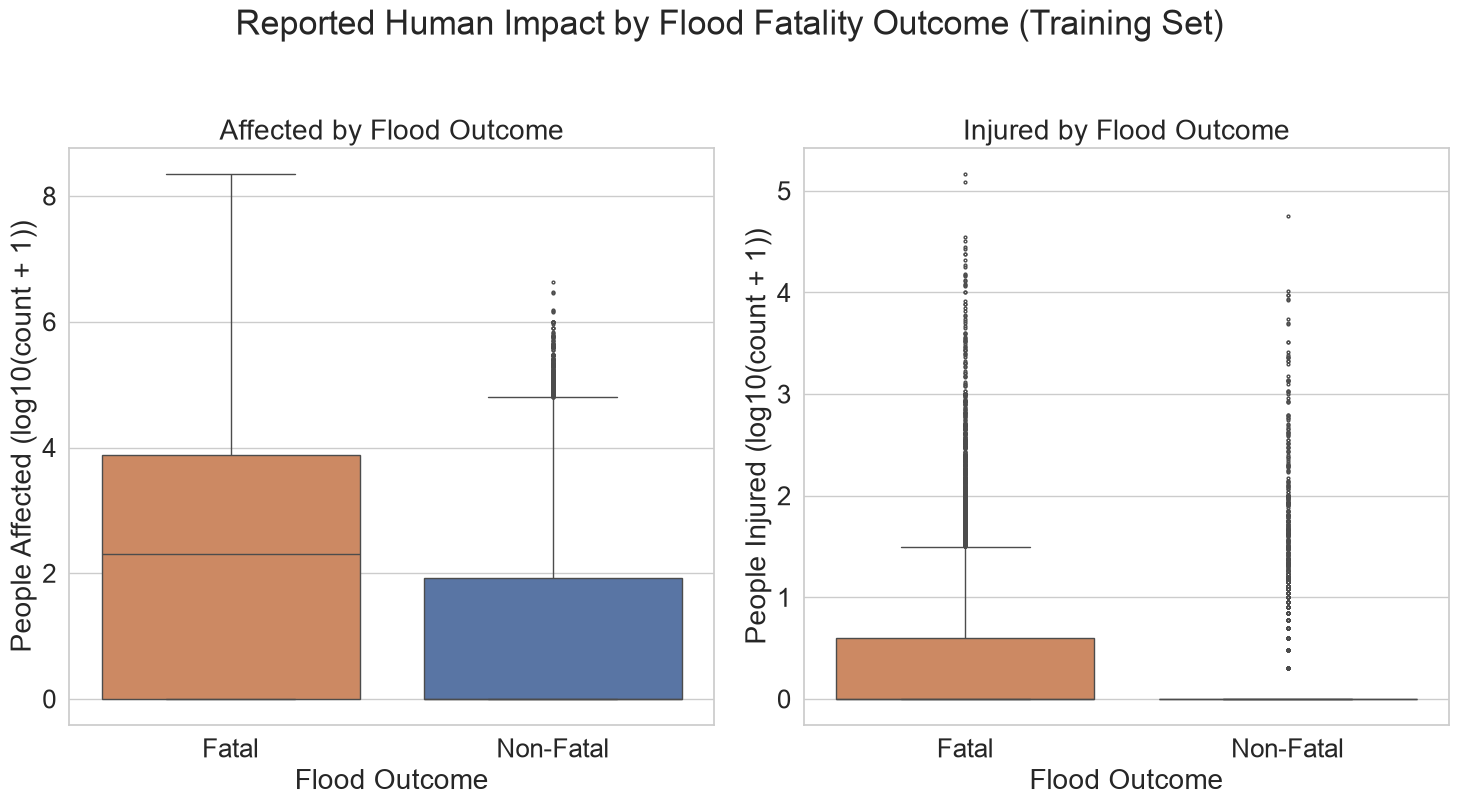

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

for ax, col, ylabel in [
    (axes[0], "Affected", "People Affected (log10(count + 1))"),
    (axes[1], "Injured", "People Injured (log10(count + 1))"),
]:
    plot_data = train_df[[col, "Outcome"]].dropna().copy()
    plot_data["log_val"] = np.log10(plot_data[col] + 1)
    sns.boxplot(
        data=plot_data,
        x="Outcome",
        y="log_val",
        hue="Outcome",
        palette=PALETTE,
        legend=False,
        fliersize=2,
        ax=ax,
    )
    ax.set_xlabel("Flood Outcome")
    ax.set_ylabel(ylabel)
    ax.set_title(f"{col} by Flood Outcome")

fig.suptitle("Reported Human Impact by Flood Fatality Outcome (Training Set)", y=1.02)
plt.tight_layout()
plt.show()

### Fig 2 - Top 10 Countries by Flood Count and Fatality Rate

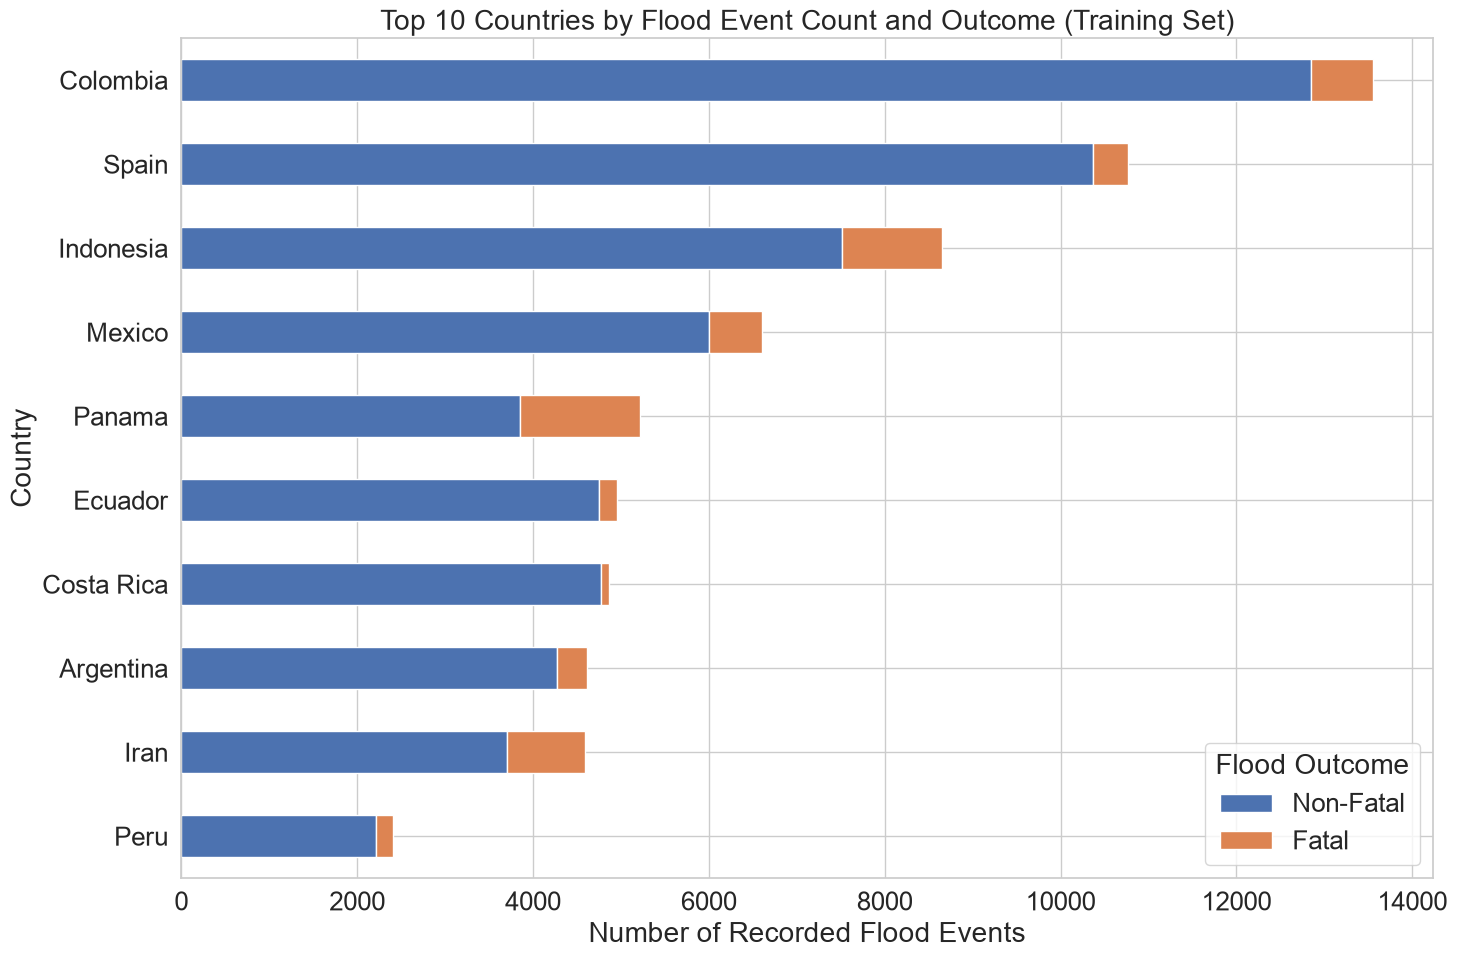

In [34]:
top_10_names = train_df["Country"].value_counts().head(10).index

country_counts = (
    train_df[train_df["Country"].isin(top_10_names)]
    .groupby(["Country", "Outcome"])
    .size()
    .unstack(fill_value=0)
    .loc[top_10_names[::-1]]  
)

fig, ax = plt.subplots(figsize=(15, 10))
country_counts[["Non-Fatal", "Fatal"]].plot(
    kind="barh",
    stacked=True,
    color=[PALETTE["Non-Fatal"], PALETTE["Fatal"]],
    ax=ax,
)

ax.set_xlabel("Number of Recorded Flood Events")
ax.set_ylabel("Country")
ax.set_title("Top 10 Countries by Flood Event Count and Outcome (Training Set)")
ax.legend(title="Flood Outcome")
plt.tight_layout()
plt.show()

### Fig 3: Flood Events and Fatality Rate Over Time (From 1900 to 2025)

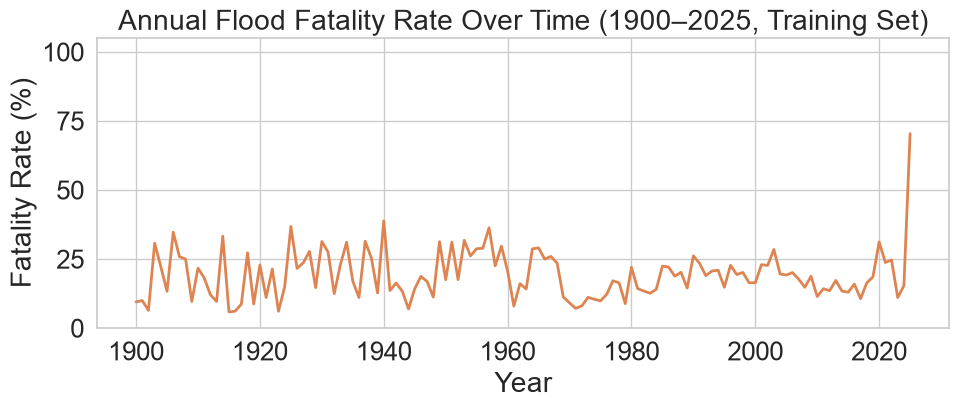

In [ ]:
yearly = (
    train_df.groupby("Year")["Fatal"]
    .mean()
    .mul(100)
    .reset_index(name="Fatality Rate (%)")
)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(
    yearly["Year"],
    yearly["Fatality Rate (%)"],
    color=PALETTE["Fatal"],
    linewidth=2,
)

ax.set_xlabel("Year")
ax.set_ylabel("Fatality Rate (%)")
ax.set_ylim(0, 105)
ax.set_title("Annual Flood Fatality Rate Over Time (1900–2025, Training Set)")
plt.tight_layout()
plt.show()